I.a) Load data and data cleaning

Output a file with all individuals and one, where we removed individuals (outliers etc.)

1.) Import libraries and create results folder


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import GEOparse

from pathlib import Path
Path("results").mkdir(exist_ok=True)

2.) Load PFC mRNA data into a dataframe

In [2]:
pfc_mrna_file = "data/GSE22521_series_matrix.txt"


pfc_mrna = pd.read_csv(
    pfc_mrna_file,
    sep="\t",
    comment="!",
    index_col=0
)


3.) Have a look at the data

In [3]:
print(pfc_mrna.shape)

print(pfc_mrna.head())

round(pfc_mrna.describe(),2)


(13042, 68)
         GSM559183  GSM559184  GSM559185  GSM559186  GSM559187  GSM559188  \
ID_REF                                                                      
7896822   3.924486   4.209343   2.558671   4.434798   3.664290   3.628356   
7897034   4.363519   4.345616   3.768352   2.571772   4.083087   4.760077   
7897044   4.601810   5.095022   4.617025   4.396065   4.889153   4.575935   
7897068   3.806804   3.950793   3.108032   4.385707   3.521073   3.809370   
7897078   5.362968   5.503288   5.244282   5.053874   5.328000   5.461167   

         GSM559189  GSM559190  GSM559191  GSM559192  ...  GSM559241  \
ID_REF                                               ...              
7896822   2.824752   3.433710   2.164794   2.957314  ...   2.536889   
7897034   4.256415   4.144009   3.522481   4.214889  ...   3.627683   
7897044   4.763925   4.740030   4.369615   4.968942  ...   4.439761   
7897068   3.074784   3.629333   2.836160   3.097626  ...   3.419544   
7897078   5.422790   5

,GSM559183,GSM559184,GSM559185,GSM559186,GSM559187,GSM559188,GSM559189,GSM559190,GSM559191,GSM559192,...,GSM559241,GSM559242,GSM559243,GSM559244,GSM559245,GSM559246,GSM559247,GSM559248,GSM559249,GSM559250
count,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,...,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00
mean,3.89,3.87,3.82,3.87,3.83,3.89,3.84,3.87,3.82,3.82,...,3.87,3.83,3.87,3.79,3.84,3.81,3.85,3.85,3.82,3.82
std,1.68,1.68,1.73,1.64,1.74,1.67,1.71,1.70,1.70,1.74,...,1.70,1.69,1.64,1.69,1.69,1.70,1.72,1.69,1.71,1.71
min,-0.96,-1.40,-2.05,-1.26,-1.05,-1.18,-2.40,-1.88,-2.12,-2.72,...,-1.19,-2.01,-2.12,-1.58,-1.59,-2.22,-1.76,-2.22,-1.91,-2.18
25%,2.73,2.70,2.53,2.74,2.57,2.73,2.58,2.67,2.54,2.52,...,2.61,2.59,2.71,2.52,2.62,2.52,2.60,2.61,2.56,2.55
50%,3.89,3.86,3.80,3.89,3.83,3.90,3.84,3.88,3.78,3.80,...,3.87,3.82,3.86,3.78,3.83,3.77,3.84,3.80,3.78,3.79
75%,5.06,5.04,5.08,5.00,5.06,5.06,5.08,5.07,5.04,5.07,...,5.08,5.02,5.00,5.02,5.04,5.05,5.08,5.06,5.04,5.06
max,9.22,10.31,10.04,10.25,9.66,9.57,9.58,9.52,9.68,9.49,...,9.91,10.21,10.25,9.49,10.39,9.67,9.78,9.60,9.54,10.09


4.) The info Table S1 states 61 individuals, but the array shows 68. 5 were tested twice. That means there is still a discrepancy. We have to find out which onese were taken out. We will use GEOparse on the info file "_family.soft"

In [4]:
gse = GEOparse.get_GEO(
    filepath="data/GSE22521_family.soft.gz",
    include_data=True,
    silent=False
)


06-Nov-2026 15:32:50 INFO GEOparse - Parsing data/GSE22521_family.soft.gz: 
06-Nov-2026 15:32:50 DEBUG GEOparse - DATABASE: GeoMiame
06-Nov-2026 15:32:50 DEBUG GEOparse - SERIES: GSE22521
06-Nov-2026 15:32:50 DEBUG GEOparse - PLATFORM: GPL6244
06-Nov-2026 15:32:53 DEBUG GEOparse - SAMPLE: GSM559183
06-Nov-2026 15:32:53 DEBUG GEOparse - SAMPLE: GSM559184
06-Nov-2026 15:32:53 DEBUG GEOparse - SAMPLE: GSM559185
06-Nov-2026 15:32:53 DEBUG GEOparse - SAMPLE: GSM559186
06-Nov-2026 15:32:53 DEBUG GEOparse - SAMPLE: GSM559187
06-Nov-2026 15:32:53 DEBUG GEOparse - SAMPLE: GSM559188
06-Nov-2026 15:32:53 DEBUG GEOparse - SAMPLE: GSM559189
06-Nov-2026 15:32:54 DEBUG GEOparse - SAMPLE: GSM559190
06-Nov-2026 15:32:54 DEBUG GEOparse - SAMPLE: GSM559191
06-Nov-2026 15:32:54 DEBUG GEOparse - SAMPLE: GSM559192
06-Nov-2026 15:32:54 DEBUG GEOparse - SAMPLE: GSM559193
06-Nov-2026 15:32:54 DEBUG GEOparse - SAMPLE: GSM559194
06-Nov-2026 15:32:54 DEBUG GEOparse - SAMPLE: GSM559195
06-Nov-2026 15:32:54 DEBUG G

5.) GEOparse creates a Python object containing the study information. gse.gsms is a a Python dictionary containing the sample objects. We check how many there are.

In [5]:
print(type(gse))
print(gse.name)
print(len(gse.gsms))


<class 'GEOparse.GEOTypes.GSE'>
GSE22521
68


6.) We check the metadata for one individual

In [6]:
test_ind = gse.gsms["GSM559248"]

print( f"Name : {test_ind.name}")
print( f"Metadata : {test_ind.metadata}")
print( f"Table : {test_ind.table}")
print( f"Columns : {test_ind.columns}")


Name : GSM559248
Metadata : {'title': ['Chimpanzee - superior frontal gyrus - 4500 days old'], 'geo_accession': ['GSM559248'], 'status': ['Public on Dec 09 2011'], 'submission_date': ['Jun 23 2010'], 'last_update_date': ['Dec 09 2011'], 'type': ['RNA'], 'channel_count': ['1'], 'source_name_ch1': ['Dissected Chimpanzee post-mortem superior frontal gyrus'], 'organism_ch1': ['Pan troglodytes'], 'taxid_ch1': ['9598'], 'characteristics_ch1': ['age: 4500 days', 'gender: m', 'tissue: superior frontal gyrus of the brain', 'post-mortem interval (hours): -', 'rna integrity number (rin): 5.9', 'batch: 1'], 'biomaterial_provider_ch1': ['BPRC, Rijswijk, Netherlands'], 'treatment_protocol_ch1': ['All human postmortem brain tissue samples were obtained from the NICHD Brain and Tissue Bank for Developmental Disorders (NICHDBB)(Baltimore, MD, USA). All subjects were defined as normal controls by forensic pathologists at the NICHDBB. No subjects with prolonged agonal state were used. Chimpanzee samples 

7.) We check the metadata to explain the discrepancy.

In [7]:
records = []

for gsm_id, gsm in gse.gsms.items():
    records.append({
        "GSM": gsm_id,
        "Title": gsm.metadata.get("title", [None])[0],
        "Source": gsm.metadata.get("source_name_ch1", [None])[0],
        "Characteristics": gsm.metadata.get("characteristics_ch1", []),
        "Description": gsm.metadata.get("description", [])
    })

sample_info = pd.DataFrame(records)

display(sample_info.head(10))

print(sample_info[["GSM", "Title"]].to_string(index=False))


,GSM,Title,Source,Characteristics,Description
0,GSM559183,Human - superior frontal gyrus - 14309 days old,Dissected Human post-mortem superior frontal g...,"[age: 14309 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
1,GSM559184,Human - superior frontal gyrus - 1630 days old,Dissected Human post-mortem superior frontal g...,"[age: 1630 days, gender: f, tissue: superior f...",[The dataset contains two prenatal individuals...
2,GSM559185,Human - superior frontal gyrus - 19457 days old,Dissected Human post-mortem superior frontal g...,"[age: 19457 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
3,GSM559186,Human - superior frontal gyrus - 19 days old,Dissected Human post-mortem superior frontal g...,"[age: 19 days, gender: f, tissue: superior fro...",[The dataset contains two prenatal individuals...
4,GSM559187,Human - superior frontal gyrus - 204 days old,Dissected Human post-mortem superior frontal g...,"[age: 204 days, gender: m, tissue: superior fr...",[The dataset contains two prenatal individuals...
5,GSM559188,Human - superior frontal gyrus - 21204 days old,Dissected Human post-mortem superior frontal g...,"[age: 21204 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
6,GSM559189,Human - superior frontal gyrus - 24090 days old,Dissected Human post-mortem superior frontal g...,"[age: 24090 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
7,GSM559190,Human - superior frontal gyrus - 28692 days old,Dissected Human post-mortem superior frontal g...,"[age: 28692 days, gender: f, tissue: superior ...",[The dataset contains two prenatal individuals...
8,GSM559191,Human - superior frontal gyrus - 29200 days old,Dissected Human post-mortem superior frontal g...,"[age: 29200 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
9,GSM559192,Human - superior frontal gyrus - 2922 days old,Dissected Human post-mortem superior frontal g...,"[age: 2922 days, gender: m, tissue: superior f...",[The dataset contains two prenatal individuals...


      GSM                                                              Title
GSM559183                    Human - superior frontal gyrus - 14309 days old
GSM559184                     Human - superior frontal gyrus - 1630 days old
GSM559185                    Human - superior frontal gyrus - 19457 days old
GSM559186                       Human - superior frontal gyrus - 19 days old
GSM559187                      Human - superior frontal gyrus - 204 days old
GSM559188                    Human - superior frontal gyrus - 21204 days old
GSM559189                    Human - superior frontal gyrus - 24090 days old
GSM559190                    Human - superior frontal gyrus - 28692 days old
GSM559191                    Human - superior frontal gyrus - 29200 days old
GSM559192                     Human - superior frontal gyrus - 2922 days old
GSM559193               Human - superior frontal gyrus - 2 days old (batch1)
GSM559194               Human - superior frontal gyrus - 2 days old (batch2)

7.i) Add species and age information to sample_info

In [8]:
sample_info["Species"] = (
    sample_info["Title"]
    .str.extract(r"^(Human|Chimpanzee|Rhesus macaque)", expand=False)
)

sample_info["Age_days"] = pd.to_numeric(
    sample_info["Title"]
    .str.extract(r"(-?\d+)\s+days?\s+old", expand=False),
    errors="coerce"
)

sample_info["Log2_Age"] = np.nan
postnatal = sample_info["Age_days"] >= 0
sample_info.loc[postnatal, "Log2_Age"] = np.log2(
    sample_info.loc[postnatal, "Age_days"] + 1
)

print(sample_info.head())


         GSM                                            Title  \
0  GSM559183  Human - superior frontal gyrus - 14309 days old   
1  GSM559184   Human - superior frontal gyrus - 1630 days old   
2  GSM559185  Human - superior frontal gyrus - 19457 days old   
3  GSM559186     Human - superior frontal gyrus - 19 days old   
4  GSM559187    Human - superior frontal gyrus - 204 days old   

                                              Source  \
0  Dissected Human post-mortem superior frontal g...   
1  Dissected Human post-mortem superior frontal g...   
2  Dissected Human post-mortem superior frontal g...   
3  Dissected Human post-mortem superior frontal g...   
4  Dissected Human post-mortem superior frontal g...   

                                     Characteristics  \
0  [age: 14309 days, gender: m, tissue: superior ...   
1  [age: 1630 days, gender: f, tissue: superior f...   
2  [age: 19457 days, gender: m, tissue: superior ...   
3  [age: 19 days, gender: f, tissue: superior fr

8.) We take the 5 individuals with duplicate measurements and check if they are correlated

In [9]:
duplicate_pairs = pd.DataFrame({
    "GSM1": [
        "GSM559193", "GSM559198", "GSM559208", "GSM559215", "GSM559223"
    ],
    "GSM2": [
        "GSM559194", "GSM559199", "GSM559209", "GSM559216", "GSM559224"
    ]
})


for _, row in duplicate_pairs.iterrows():
    gsm1 = row["GSM1"]
    gsm2 = row["GSM2"]

    correlation = pfc_mrna[gsm1].corr(pfc_mrna[gsm2])

    print(gsm1, gsm2, "Correlation:", round(correlation, 4))


GSM559193 GSM559194 Correlation: 0.9415
GSM559198 GSM559199 Correlation: 0.9454
GSM559208 GSM559209 Correlation: 0.9821
GSM559215 GSM559216 Correlation: 0.9721
GSM559223 GSM559224 Correlation: 0.9764


8.) Another individual was not in Table S1, we identified it using an LLM. It is GSM559211 who is 1487 days or 4 years and 17 days old. 
    We make an exclusion list and a reduced table and check for missing values and duplicates. We also take out the prenatal macaque GSM559214. The second prenatal macaque is removed as an outlier. 

In [10]:
exclusion_list = ["GSM559194", 
                  "GSM559199", 
                  "GSM559209", 
                  "GSM559216", 
                  "GSM559224", 
                  "GSM559211", #unmatched
                  "GSM559214"] # prenatal macaque

pfc_mrna_clean = pfc_mrna.drop(columns=exclusion_list)

pfc_mrna_clean.columns

print(pfc_mrna_clean.isna().sum().sum())

print("Duplicate feature IDs:",
      pfc_mrna_clean.index.duplicated().sum())

print("Duplicate GSM IDs:",
      pfc_mrna_clean.columns.duplicated().sum())


0
Duplicate feature IDs: 0
Duplicate GSM IDs: 0


9.) We make a new metadata table and look at the age distribution

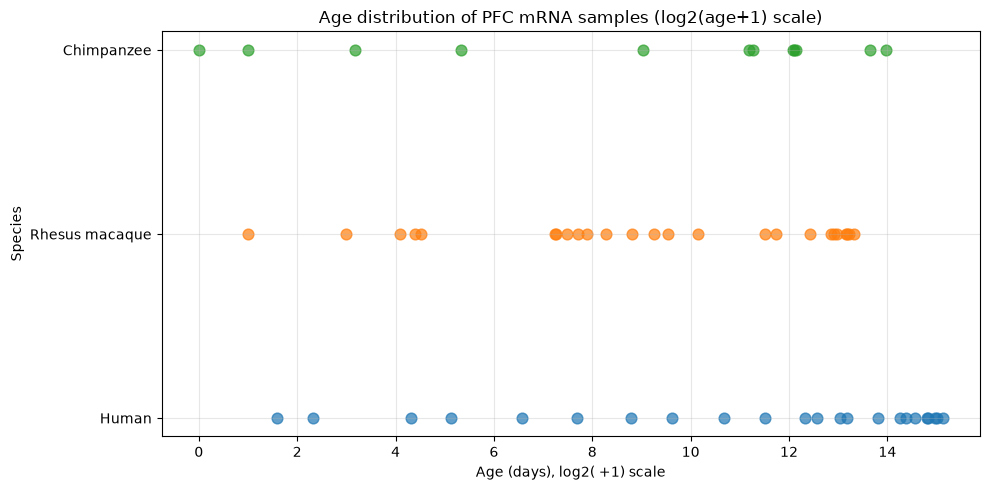

In [11]:
sample_info_clean = sample_info[
    ~sample_info["GSM"].isin(exclusion_list)
].copy()

plt.figure(figsize=(10, 5))

for species in sample_info_clean["Species"].unique():
    
    subset = sample_info_clean[
        sample_info_clean["Species"] == species
    ]
    
    plt.scatter(
        subset["Log2_Age"],
        [species] * len(subset),
        label=species,
        s=60,
        alpha=0.7
    )

plt.xlabel("Age (days), log2( +1) scale")
plt.ylabel("Species")
plt.title("Age distribution of PFC mRNA samples (log2(age+1) scale)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


10.) Trying to find an outlier macaque. We extract the species data and correlate all individuals

In [12]:
species_ids = {}
corr = {}
median_corr = {}

for i in sample_info_clean["Species"].unique():

    info = sample_info_clean[
        sample_info_clean["Species"] == i
    ].copy()

    species_ids[i] = info["GSM"].tolist()

    spec_mrna = pfc_mrna_clean[species_ids[i]]

    corr[i] = spec_mrna.corr()

    median_corr[i] = corr[i].mask(
        np.eye(len(corr[i]), dtype=bool)
    ).median()

    print(f"\nSpecies: {i}")
    display(median_corr[i].sort_values().head(10))



Species: Human


GSM559193    0.845729
GSM559186    0.877110
GSM559201    0.906572
GSM559191    0.920674
GSM559197    0.921499
GSM559200    0.927352
GSM559207    0.928219
GSM559198    0.928756
GSM559185    0.933086
GSM559202    0.933726
dtype: float64


Species: Rhesus macaque


GSM559225    0.883975
GSM559229    0.925011
GSM559232    0.927480
GSM559236    0.931367
GSM559226    0.932408
GSM559233    0.935296
GSM559227    0.935392
GSM559238    0.936787
GSM559218    0.938325
GSM559230    0.939320
dtype: float64


Species: Chimpanzee


GSM559245    0.917097
GSM559250    0.919824
GSM559242    0.922950
GSM559239    0.928499
GSM559241    0.935504
GSM559243    0.946899
GSM559244    0.947299
GSM559246    0.947619
GSM559240    0.949751
GSM559248    0.953120
dtype: float64

Check correlation between the two human outliers GSM559193 (2 days old) and GSM559186 (19 days old) and GSM559201 (4 days old) 

In [13]:
sample1 = "GSM559193"
sample2 = "GSM559186"

r = pfc_mrna[sample1].corr(pfc_mrna[sample2])

print("Pearson correlation:", r)

sample1 = "GSM559193"
sample2 = "GSM559201"

r = pfc_mrna[sample1].corr(pfc_mrna[sample2])

print("Pearson correlation:", r)

sample1 = "GSM559186"
sample2 = "GSM559201"

r = pfc_mrna[sample1].corr(pfc_mrna[sample2])

print("Pearson correlation:", r)

human_samples = sample_info.loc[
    sample_info["Species"] == "Human",
    "GSM"
]

corr_19days = (
    pfc_mrna[human_samples]
    .corr()["GSM559186"]
    .drop("GSM559186")
)

# Combine correlations with ages
corr_info = sample_info.set_index("GSM").loc[corr_19days.index, [
    "Age_days", "Log2_Age"
]].copy()

corr_info["Correlation"] = corr_19days

# Sort by age
corr_info = corr_info.sort_values("Correlation")

corr_info.tail()


Pearson correlation: 0.8635713628008224
Pearson correlation: 0.9466211083109638
Pearson correlation: 0.8944865317671229


,Age_days,Log2_Age,Correlation
GSM559194,2,1.584963,0.901508
GSM559200,443,8.794416,0.902535
GSM559197,34,5.129283,0.908567
GSM559187,204,7.679480,0.909755
GSM559207,94,6.569856,0.924734


11.) The analysis reveals 3 outliers, 2 humans and 1 macaque, which are taken out. 

In [14]:
outliers = [
    "GSM559193",  # Human, median correlation 0.845729, age 2 days old
    "GSM559186",  # Human, median correlation 0.877110, age 19 days old
    "GSM559225"   # Prenatal macaque, -30 days; median correlation 0.885962
]

sample_info_clean.loc[
    sample_info_clean["GSM"].isin(outliers)
]


,GSM,Title,Source,Characteristics,Description,Species,Age_days,Log2_Age
3,GSM559186,Human - superior frontal gyrus - 19 days old,Dissected Human post-mortem superior frontal g...,"[age: 19 days, gender: f, tissue: superior fro...",[The dataset contains two prenatal individuals...,Human,19,4.321928
10,GSM559193,Human - superior frontal gyrus - 2 days old (b...,Dissected Human post-mortem superior frontal g...,"[age: 2 days, gender: m, tissue: superior fron...",[The dataset contains two prenatal individuals...,Human,2,1.584963
42,GSM559225,Rhesus macaque - superior frontal gyrus - -30 ...,Dissected Rhesus macaque post-mortem superior ...,[age: -30 days (prenatal individual; predicted...,[The dataset contains two prenatal individuals...,Rhesus macaque,-30,NaN


12.) We make a new datatable by taking out the three outliers. Selectin criterion: Median correlation within species higher than 90%

/tmp/ipykernel_49204/4076486197.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(


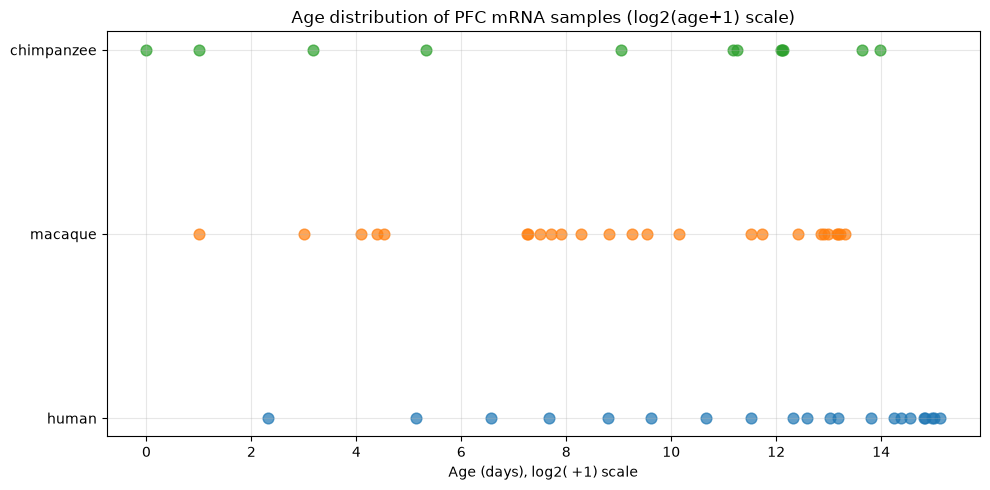

<class 'pandas.DataFrame'>
Index: 13042 entries, 7896822 to 8177222
Data columns (total 58 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   GSM559183  13042 non-null  float64
 1   GSM559184  13042 non-null  float64
 2   GSM559185  13042 non-null  float64
 3   GSM559187  13042 non-null  float64
 4   GSM559188  13042 non-null  float64
 5   GSM559189  13042 non-null  float64
 6   GSM559190  13042 non-null  float64
 7   GSM559191  13042 non-null  float64
 8   GSM559192  13042 non-null  float64
 9   GSM559195  13042 non-null  float64
 10  GSM559196  13042 non-null  float64
 11  GSM559197  13042 non-null  float64
 12  GSM559198  13042 non-null  float64
 13  GSM559200  13042 non-null  float64
 14  GSM559201  13042 non-null  float64
 15  GSM559202  13042 non-null  float64
 16  GSM559203  13042 non-null  float64
 17  GSM559204  13042 non-null  float64
 18  GSM559205  13042 non-null  float64
 19  GSM559206  13042 non-null  float64
 20  GSM559207  130

In [15]:
sample_info_filt = sample_info_clean[
    ~sample_info_clean["GSM"].isin(outliers)
].copy()

plt.figure(figsize=(10, 5))

for species in sample_info_filt["Species"].unique():
    
    subset = sample_info_filt[
        sample_info_filt["Species"] == species
    ]
    
    plt.scatter(
        subset["Log2_Age"],
        [species] * len(subset),
        label=species,
        s=60,
        alpha=0.7
    )

plt.xlabel("Age (days), log2( +1) scale")
plt.gca().set_yticklabels(
    ["human", "macaque", "chimpanzee"]
)
plt.title("Age distribution of PFC mRNA samples (log2(age+1) scale)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

pfc_mrna_filt = pfc_mrna_clean.drop(columns=outliers)
pfc_mrna_filt.index = pfc_mrna_filt.index.astype(str)

pfc_mrna_filt.info()


13.) We now match the identifiers to genes using the annotation from the original data. The annotations are is GPL6244, saved as GPL6244.txt.gz

In [16]:
# Getting the file using GEOparse, set index to string

gpl = GEOparse.get_GEO(
    filepath="data/GPL6244.txt.gz"
)

annotation = gpl.table.copy()
#annotation.index = annotation.index.astype(str)


print(annotation.shape)
display(annotation.head(40))

# show columns
print(annotation.columns.tolist())

# show how many expression ids can be found in the annotation

expression_ids = set(pfc_mrna_filt.index)
platform_ids = set(annotation["ID"].astype(str))

print("Expression features:", len(expression_ids))

print(
    "Features found in annotation:",
    len(expression_ids & platform_ids)
)

print(
    "Features not found:",
    len(expression_ids - platform_ids)
)

#copy the pfc  annotation into a separate dataframe annotation_pfc

annotation_pfc = annotation.copy()

annotation_pfc["ID"] = annotation_pfc["ID"].astype(str)

annotation_pfc = annotation_pfc.set_index("ID").loc[
    pfc_mrna_filt.index
].copy()

print(annotation_pfc.shape)


06-Nov-2026 15:32:57 INFO GEOparse - Parsing data/GPL6244.txt.gz: 
06-Nov-2026 15:32:57 DEBUG GEOparse - PLATFORM: GPL6244


(33297, 12)


,ID,GB_LIST,SPOT_ID,seqname,RANGE_GB,RANGE_STRAND,RANGE_START,RANGE_STOP,total_probes,gene_assignment,mrna_assignment,category
0,7896736,NaN,chr1:53049-54936,chr1,NC_000001.10,+,53049,54936,7,---,NONHSAT060105 // NONCODE // Non-coding transcr...,main
1,7896738,NaN,chr1:63015-63887,chr1,NC_000001.10,+,63015,63887,31,ENST00000328113 // OR4G2P // olfactory recepto...,ENST00000328113 // ENSEMBL // havana:known chr...,main
2,7896740,"NM_001004195,NM_001005240,NM_001005484,BC13684...",chr1:69091-70008,chr1,NC_000001.10,+,69091,70008,24,"NM_001004195 // OR4F4 // olfactory receptor, f...",NM_001004195 // RefSeq // Homo sapiens olfacto...,main
3,7896742,"NR_024437,XM_006711854,XM_006726377,XR_430662,...",chr1:334129-334296,chr1,NC_000001.10,+,334129,334296,6,NR_024437 // LOC728323 // uncharacterized LOC7...,NR_024437 // RefSeq // Homo sapiens uncharacte...,main
4,7896744,"NM_001005221,NM_001005224,NM_001005277,NM_0010...",chr1:367659-368597,chr1,NC_000001.10,+,367659,368597,36,"NM_001005221 // OR4F29 // olfactory receptor, ...",NM_001005221 // RefSeq // Homo sapiens olfacto...,main
5,7896746,"AK074482,NC_001807",chr1:564951-565019,chr1,NC_000001.10,+,564951,565019,28,ENST00000387377 // MT-TM // mitochondrially en...,ENST00000387377 // ENSEMBL // mt_genbank_impor...,main
6,7896748,NC_001807,chr1:566062-566129,chr1,NC_000001.10,+,566062,566129,24,ENST00000387382 // MT-TW // mitochondrially en...,ENST00000387382 // ENSEMBL // mt_genbank_impor...,main
7,7896750,NC_001807,chr1:568069-568136,chr1,NC_000001.10,+,568069,568136,28,ENST00000387419 // MT-TD // mitochondrially en...,ENST00000387419 // ENSEMBL // mt_genbank_impor...,main
8,7896752,"M37726,NC_001807",chr1:568844-568913,chr1,NC_000001.10,+,568844,568913,24,ENST00000387421 // MT-TK // mitochondrially en...,ENST00000387421 // ENSEMBL // mt_genbank_impor...,main
9,7896754,"AK026836,AK290103",chr1:721406-721912,chr1,NC_000001.10,+,721406,721912,23,ENST00000540997 // LOC100287497 // uncharacter...,ENST00000540997 // ENSEMBL // havana:known chr...,main


['ID', 'GB_LIST', 'SPOT_ID', 'seqname', 'RANGE_GB', 'RANGE_STRAND', 'RANGE_START', 'RANGE_STOP', 'total_probes', 'gene_assignment', 'mrna_assignment', 'category']
Expression features: 13042
Features found in annotation: 13042
Features not found: 0
(13042, 11)


14.) Extract gene names from column 'gene_assignment. Create function and extract name and number of genes

In [17]:
def extract_genes(assignment):
    if pd.isna(assignment) or assignment.strip() == "---":
        return []

    entries = assignment.split(" /// ")
    genes = set()

    for entry in entries:
        parts = entry.split(" // ")

        if len(parts) >= 2:
            gene = parts[1].strip()

            if gene and gene != "---":
                genes.add(gene)

    return sorted(genes)

#Extract gene names and store in "Gene", number of genes and store in "N_genes" and "Gene", if there is a single gene

annotation_pfc["Genes"] = (
    annotation_pfc["gene_assignment"].apply(extract_genes)
)

annotation_pfc["N_genes"] = (
    annotation_pfc["Genes"].apply(len)
)

annotation_pfc["Gene"] = (
    annotation_pfc["Genes"].apply(
        lambda x: x[0] if len(x) == 1 else None
    )
)

annotation_pfc.sample(5)


,GB_LIST,SPOT_ID,seqname,RANGE_GB,RANGE_STRAND,RANGE_START,RANGE_STOP,total_probes,gene_assignment,mrna_assignment,category,Genes,N_genes,Gene
ID_REF,,,,,,,,,,,,,,
8035553,"NM_007263,NM_199442,NM_199444,AF092438,AK22258...",chr19:19010323-19030208,chr19,NC_000019.9,-,19010323,19030208,26,"NM_007263 // COPE // coatomer protein complex,...",NM_007263 // RefSeq // Homo sapiens coatomer p...,main,[COPE],1,COPE
7969479,"BC115358,NR_026983",chr13:77502200-77502835,chr13,NC_000013.10,+,77502200,77502835,26,BC115358 // BTF3P11 // basic transcription fac...,BC115358 // GenBank // Homo sapiens basic tran...,main,[BTF3P11],1,BTF3P11
8162601,"AY554164,AY554165,BC126141,NM_153695",chr9:99148223-99180669,chr9,NC_000009.11,-,99148223,99180669,31,AY554164 // ZNF367 // zinc finger protein 367 ...,AY554164 // GenBank // Homo sapiens C2H2 zinc ...,main,[ZNF367],1,ZNF367
8102730,"NM_152778,AK294184,AK294439,AK294527,AK294957,...",chr4:128841577-128887104,chr4,NC_000004.11,-,128841577,128887104,34,NM_152778 // MFSD8 // major facilitator superf...,NM_152778 // RefSeq // Homo sapiens major faci...,main,[MFSD8],1,MFSD8
8114856,"NM_001029869,XM_005268381,BC130586,BC130588,BC...",chr5:145463876-145483946,chr5,NC_000005.9,-,145463876,145483946,28,NM_001029869 // PLAC8L1 // PLAC8-like 1 // 5q3...,NM_001029869 // RefSeq // Homo sapiens PLAC8-l...,main,[PLAC8L1],1,PLAC8L1


15.) We only retain genes, where the number of genes is one, otherwise this would create ambiguity

In [18]:
#save the annotations in unique_features

unique_features = annotation_pfc[
    annotation_pfc["N_genes"] == 1
].copy()

unique_features.head()

# Find the genes represented by multiple features

gene_counts = unique_features["Gene"].value_counts()

print("Genes total:", len(set(unique_features["Gene"])))
print("Genes represented by multiple features:",
      (gene_counts > 1).sum())


Genes total: 11783
Genes represented by multiple features: 116


16.) We decide to retain only the genes that have single feature

In [19]:
# Select genes represented by exactly one feature
single_genes = gene_counts[gene_counts == 1].index

# Keep their annotations
single_features = unique_features[
    unique_features["Gene"].isin(single_genes)
].copy()

print("Genes retained:", len(single_features))

# Select the retained features
mrna_gene = pfc_mrna_filt.loc[single_features.index].copy()

# Replace feature identifiers with gene symbols
mrna_gene.index = single_features["Gene"].values
mrna_gene.index.name = "Gene"

print(mrna_gene.shape)


Genes retained: 11667
(11667, 58)


17. a) Export the all-sample inputs required by 1b

The same gene annotation is applied to all 68 original arrays. These files retain samples excluded from the strict 58-sample cohort so that 1b can define its separate developmental cohort.


In [20]:
# Prepare the original 68-sample expression matrix
pfc_mrna_all_samples = pfc_mrna.copy()

pfc_mrna_all_samples.index = (
    pfc_mrna_all_samples.index
    .astype(str)
    .str.strip()
)

pfc_mrna_all_samples.columns = (
    pfc_mrna_all_samples.columns
    .astype(str)
    .str.strip()
)

feature_ids = single_features.index.astype(str)
missing_features = feature_ids.difference(
    pfc_mrna_all_samples.index
)

assert len(missing_features) == 0, (
    f"Missing expression features: {missing_features.tolist()}"
)

# Apply the same gene filtering used for the strict matrix
mrna_gene_all_samples = pfc_mrna_all_samples.loc[
    feature_ids
].copy()

mrna_gene_all_samples.index = single_features["Gene"].values
mrna_gene_all_samples.index.name = "Gene"

# Prepare and align the complete metadata
expression_samples = (
    mrna_gene_all_samples.columns
    .astype(str)
    .str.strip()
    .tolist()
)

sample_info_all_samples = sample_info.copy()
sample_info_all_samples["GSM"] = (
    sample_info_all_samples["GSM"]
    .astype(str)
    .str.strip()
)

assert not sample_info_all_samples["GSM"].duplicated().any(), (
    "Duplicate GSM identifiers were found in the metadata."
)

missing_metadata = pd.Index(expression_samples).difference(
    sample_info_all_samples["GSM"]
)
assert len(missing_metadata) == 0, (
    f"Missing metadata: {missing_metadata.tolist()}"
)

sample_info_all_samples = (
    sample_info_all_samples
    .set_index("GSM")
    .loc[expression_samples]
    .copy()
)

# Add GSM explicitly instead of relying on reset_index()
sample_info_all_samples.insert(0, "GSM", expression_samples)
sample_info_all_samples = sample_info_all_samples.reset_index(drop=True)

metadata_samples = (
    sample_info_all_samples["GSM"]
    .astype(str)
    .tolist()
)

assert mrna_gene_all_samples.shape[0] == len(single_features)
assert mrna_gene_all_samples.shape[1] == 68, (
    f"Expected 68 expression samples, found "
    f"{mrna_gene_all_samples.shape[1]}."
)
assert len(sample_info_all_samples) == 68, (
    f"Expected 68 metadata rows, found "
    f"{len(sample_info_all_samples)}."
)
assert not sample_info_all_samples["GSM"].isna().any()
assert metadata_samples == expression_samples, (
    "The metadata and expression samples are not in the same order."
)

mrna_gene_all_samples.to_csv(
    "results/pfc_mrna_gene_expression_all_samples.csv"
)

sample_info_all_samples.to_csv(
    "results/pfc_mrna_sample_info_all_samples.csv",
    index=False
)

print(
    "Exported all-sample expression matrix:",
    mrna_gene_all_samples.shape
)
print(
    "Exported all-sample metadata:",
    sample_info_all_samples.shape
)


Exported all-sample expression matrix: (11667, 68)
Exported all-sample metadata: (68, 8)


17. b) Export the final 58-sample expression matrix, matching metadata and gene annotation

Only the final filtered metadata are written. The metadata rows are placed in exactly the same order as the expression columns, and explicit checks prevent an unfiltered or misaligned export.


In [21]:
# Standardize the expression-sample identifiers
mrna_gene.columns = (
    mrna_gene.columns
    .astype(str)
    .str.strip()
)

strict_samples = mrna_gene.columns.tolist()

# Reconstruct the final metadata from the unmodified metadata table
sample_info_export = sample_info_clean[
    ~sample_info_clean["GSM"].isin(outliers)
].copy()

sample_info_export["GSM"] = (
    sample_info_export["GSM"]
    .astype(str)
    .str.strip()
)

# Check for duplicate or missing identifiers
assert not sample_info_export["GSM"].duplicated().any(), (
    "Duplicate GSM identifiers were found."
)

missing_metadata = pd.Index(strict_samples).difference(
    sample_info_export["GSM"]
)

assert len(missing_metadata) == 0, (
    f"Missing metadata: {missing_metadata.tolist()}"
)

# Align the metadata with the expression columns
sample_info_export = (
    sample_info_export
    .set_index("GSM")
    .loc[strict_samples]
    .copy()
)

# Restore GSM explicitly as a normal column
sample_info_export.insert(
    0,
    "GSM",
    strict_samples
)

sample_info_export = sample_info_export.reset_index(drop=True)

# Use the aligned table in the following analysis
sample_info_filt = sample_info_export.copy()

# Final checks
assert mrna_gene.shape[0] == len(single_features)
assert mrna_gene.shape[1] == 58
assert len(sample_info_filt) == 58
assert sample_info_filt["GSM"].tolist() == strict_samples

# Export the three final files
mrna_gene.to_csv(
    "results/pfc_mrna_gene_expression.csv"
)

sample_info_filt.to_csv(
    "results/pfc_mrna_sample_info.csv",
    index=False
)

single_features.to_csv(
    "results/pfc_mrna_gene_annotation.csv"
)

print(
    "Exported results/pfc_mrna_gene_expression.csv:",
    mrna_gene.shape
)

print(
    "Exported results/pfc_mrna_sample_info.csv:",
    sample_info_filt.shape
)

print(
    "Exported results/pfc_mrna_gene_annotation.csv:",
    single_features.shape
)


Exported results/pfc_mrna_gene_expression.csv: (11667, 58)
Exported results/pfc_mrna_sample_info.csv: (58, 8)
Exported results/pfc_mrna_gene_annotation.csv: (11667, 14)


18.) Exploratory analysis: variation explained by species and age


In [22]:
#Transpose matrix
Y = mrna_gene.T

print(Y.shape)

#align metadata
info = sample_info_filt.set_index("GSM").loc[Y.index]

# get dummy veriables
age = np.log2(info["Age_days"].astype(float) + 1)

species = pd.get_dummies(
    info["Species"],
    drop_first=True,
    dtype=float
)

# create design matrices
X_species = species

X_age = age.to_frame(name="Log2_Age")

X_both = pd.concat([species, X_age], axis=1)

# use linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# fit species model
model_species = LinearRegression()
model_species.fit(X_species, Y)

Y_pred_species = model_species.predict(X_species)

#Calculate R^2 value for every gene
r2_species = r2_score(
    Y,
    Y_pred_species,
    multioutput="raw_values"
)

#fit age model

model_age = LinearRegression()
model_age.fit(X_age, Y)

r2_age = r2_score(
    Y,
    model_age.predict(X_age),
    multioutput="raw_values"
)

#fit both age and species

model_both = LinearRegression()
model_both.fit(X_both, Y)

r2_both = r2_score(
    Y,
    model_both.predict(X_both),
    multioutput="raw_values"
)

# create regression results table

regression_results = pd.DataFrame({
    "Gene": Y.columns,
    "R2_species": r2_species,
    "R2_age": r2_age,
    "R2_both": r2_both
}).set_index("Gene")

# additional contribution of age and species

regression_results["Age_given_species"] = (
    regression_results["R2_both"]
    - regression_results["R2_species"]
)

regression_results["Species_given_age"] = (
    regression_results["R2_both"]
    - regression_results["R2_age"]
)

# summmarize results

display(regression_results.describe())


(58, 11667)


,R2_species,R2_age,R2_both,Age_given_species,Species_given_age
count,1.166700e+04,1.166700e+04,11667.000000,1.166700e+04,11667.000000
mean,2.582413e-01,1.297754e-01,0.382416,1.241752e-01,0.252641
std,2.171526e-01,1.647616e-01,0.225715,1.649000e-01,0.211247
min,9.311234e-07,5.703993e-11,0.000243,9.452286e-10,0.000003
25%,7.993438e-02,1.270220e-02,0.191497,1.021090e-02,0.078991
50%,1.956842e-01,6.014409e-02,0.364221,5.254869e-02,0.191986
75%,3.932628e-01,1.837314e-01,0.554296,1.720011e-01,0.381288
max,9.779949e-01,8.785160e-01,0.978258,8.752202e-01,0.955322
